In [ ]:
import pandas as pd
import numpy as np

!gdown 1ZdhRqYv-JizWV6DxO6C4R_k1kxPhmlF2

Using cookies from /Users/siddharth/.cache/gdown/cookies.txt
Downloading...
From: https://drive.google.com/uc?id=1ZdhRqYv-JizWV6DxO6C4R_k1kxPhmlF2
To: /Users/siddharth/Documents/Siddharth/MyNotes/MyNotes/AI_ML/Jupyter_Notebooks/CaseStudy/Logistic Regression/multiclass.csv
100%|█████████████████████████████████████| 14.6k/14.6k [00:00<00:00, 1.52MB/s]


In [3]:
df = pd.read_csv('multiclass.csv')
df.head()

,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen,class
0,3,12669,9656,7561,214,2674,1338,2
1,3,7057,9810,9568,1762,3293,1776,2
2,3,6353,8808,7684,2405,3516,7844,2
3,3,13265,1196,4221,6404,507,1788,1
4,3,22615,5410,7198,3915,1777,5185,1


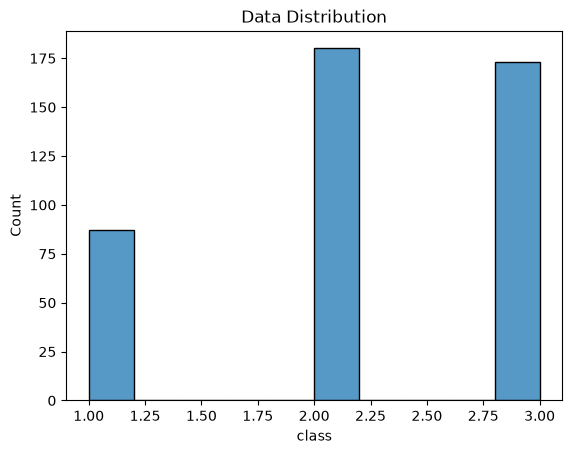

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(data=df, x="class")

plt.title('Data Distribution')
plt.show()

<details>
<summary><b>Explanation</b></summary>
The image shows Python code using `seaborn` and `matplotlib.pyplot` to visualize the frequency distribution of a categorical column (`"class"`) from a DataFrame (`df`), along with the resulting histogram.

### Code Breakdown

* **`import seaborn as sns` & `import matplotlib.pyplot as plt**`: Imports libraries for statistical data visualization (`seaborn`) and figure management (`matplotlib`).


* **`sns.histplot(data=df, x="class")`**: Plots a histogram counting occurrences of each unique value in the `class` column.


* **`plt.title('Data Distribution')`**: Adds the title at the top of the chart.


* **`plt.show()`**: Displays the generated plot.



---

### Chart Interpretation

The chart represents a discrete categorical or multi-class target variable with three distinct classes: **1.00**, **2.00**, and **3.00**.

* **Class 1.00**: Contains approximately **87** samples (the minority class).


* **Class 2.00**: Contains approximately **180** samples (the largest class).


* **Class 3.00**: Contains approximately **173** samples.



**Key Takeaway:** The dataset has moderate class imbalance, with Class 1 having roughly half as many instances as Class 2 or Class 3.
</details>

In [5]:
X=df[['Region', 'Fresh',    'Milk', 'Grocery',  'Frozen',   'Detergents_Paper', 'Delicassen' ]].copy()
y=df[['class']].copy()

<details>
<summary><b>Explanation</b></summary>
Using `.copy()` creates an independent DataFrame in memory rather than a view (or reference) linked to the original DataFrame `df`.

---

### Primary Reasons to Use `.copy()`

* **Prevents `SettingWithCopyWarning**`: If you slice a DataFrame without `.copy()` and later modify values, add new columns, or scale features (e.g., `X['Fresh'] = np.log(X['Fresh'])`), pandas often throws a `SettingWithCopyWarning` because it cannot guarantee whether you are modifying a copy or the original data. Explicitly calling `.copy()` suppresses this ambiguity.
* **Avoids Unintended Side Effects**: Without a copy, changes made to `X` or `y` (such as encoding categorical features, dropping rows, filling nulls, or applying feature scaling) could accidentally overwrite the data inside `df`.
* **Protects from Changes to the Original Data**: If you later manipulate or overwrite `df`, `X` and `y` remain unchanged and reliable for machine learning pipelines (like `train_test_split`).

---

### Comparison Example

**Without `.copy()`:**

```python
X = df[['Region', 'Fresh', 'Milk']]
X['Fresh'] = X['Fresh'] / 1000  # Raises SettingWithCopyWarning; may alter df['Fresh']

```

**With `.copy()`:**

```python
X = df[['Region', 'Fresh', 'Milk']].copy()
X['Fresh'] = X['Fresh'] / 1000  # Completely safe; leaves df untouched

```

*(Note: For the target variable `y`, if you intend to pass it to scikit-learn models, using `y = df['class'].copy()` produces a 1D Series instead of a 2D single-column DataFrame `df[['class']]`, avoiding common shape mismatch warnings).*
</details>


In [14]:
from sklearn.model_selection import train_test_split

X_train_val, X_test, y_train_val, y_test = train_test_split(X,y,test_size=0.25, random_state=42)

X_train, X_val, y_train, y_val = train_test_split(X_train_val,y_train_val,test_size=0.25, random_state=42)

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)


(247, 7) (247, 1)
(83, 7) (83, 1)
(110, 7) (110, 1)


In [15]:
from sklearn.preprocessing import StandardScaler


std =  StandardScaler()

X_train_scaled = std.fit_transform(X_train)
X_val_scaled = std.transform(X_val.values)
X_test_scaled = std.transform(X_test.values)

y_train = y_train.values[:,0]
y_val = y_val.values[:,0]
y_test = y_test.values[:,0]

/Users/siddharth/Documents/Siddharth/MyNotes/MyNotes/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(
/Users/siddharth/Documents/Siddharth/MyNotes/MyNotes/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2827: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


In [16]:
X_train_scaled

array([[ 0.65073249,  1.57410411,  1.16701682, ..., -0.51514369,
        -0.59988229, -0.05538022],
       [ 0.65073249,  0.12703055, -0.18385118, ..., -0.54667714,
        -0.55703425,  0.45515047],
       [ 0.65073249,  3.17944329, -0.2277037 , ...,  0.55794326,
        -0.38564206, -0.06827666],
       ...,
       [ 0.65073249,  0.26716693,  0.76213187, ..., -0.21139683,
         0.79700732, -0.26172321],
       [ 0.65073249,  2.46269423, -0.23506252, ..., -0.47506203,
        -0.05108105, -0.10360168],
       [ 0.65073249, -1.00144969, -0.78502123, ..., -0.42909158,
        -0.59923308, -0.44423583]], shape=(247, 7))

In [17]:
X_val_scaled[50]

array([ 0.65073249, -0.49151135, -0.48436111, -0.6888578 , -0.29269993,
       -0.54361718, -0.26957321])

In [18]:
y_val[50]

np.int64(3)

In [19]:
np.sqrt(np.sum(X_val_scaled[50]-X_train_scaled[0])**2)

np.float64(4.052836961334906)

In [20]:
dist=np.sqrt(np.sum((X_val_scaled[50]-X_train_scaled)**2,axis=1))

In [21]:
dist.shape

(247,)

In [22]:
distances=[(dist[i],y_train[i]) for i in range(len(X_train))]
distances[:5]

[(np.float64(2.6930706679191183), np.int64(2)),
 (np.float64(1.099679602476764), np.int64(1)),
 (np.float64(3.796996125733141), np.int64(2)),
 (np.float64(1.2722623030554996), np.int64(3)),
 (np.float64(0.6657356972011926), np.int64(3))]

In [23]:
sorted_distances=sorted(distances)
top_5_distance=sorted_distances[:5]

In [24]:
for cl in top_5_distance:
  print(cl[1])


3
3
3
3
3


In [25]:
from sklearn.neighbors import KNeighborsClassifier
knn_model=KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](3,)","[1,2,3]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [26]:
sklearn_predictions=knn_model.predict(X_val_scaled)
print(sklearn_predictions)
print(len(sklearn_predictions))

[3 2 2 2 3 2 3 1 3 3 2 2 3 3 2 3 3 3 2 3 1 1 2 2 1 2 3 2 2 2 2 3 2 2 2 3 2
 1 3 3 3 3 1 2 3 2 1 3 2 3 3 2 3 3 2 2 3 3 3 1 1 2 1 3 3 2 2 1 3 2 2 2 2 2
 3 2 1 3 1 2 3 3 2]
83


In [27]:
from sklearn.metrics import accuracy_score

sklearn_accuracy = accuracy_score(y_val, sklearn_predictions)

print(f"Accuracy of the scikit-learn KNN model on the validation set: {sklearn_accuracy}")

Accuracy of the scikit-learn KNN model on the validation set: 0.9156626506024096


Text(0, 0.5, 'Accuracy')

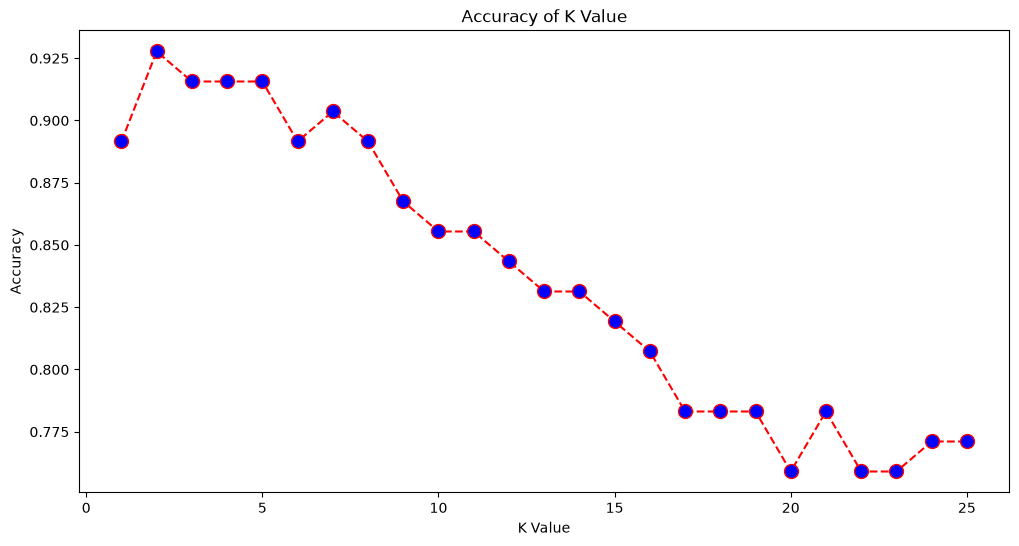

In [28]:
Acc = []

for i in range(1, 51, 2):
  knn = KNeighborsClassifier(n_neighbors=i)

  # Train the model on the scaled training data
  knn.fit(X_train_scaled, y_train)

  Acc.append(knn.score(X_val_scaled,y_val))



plt.figure(figsize=(12, 6))
plt.plot(range(1, 26), Acc, color='red', linestyle='dashed', marker='o',
         markerfacecolor='blue', markersize=10)
plt.title('Accuracy of K Value')
plt.xlabel('K Value')
plt.ylabel('Accuracy')